# FP-Growth association mining

We study co-occurring prison-system characteristics in aggregate state-year profiles. We report the baseline outcome first, compare declared thresholds, then interpret the separately labeled exploratory rules. This notebook executes the mining code and generates its own figures; saved images are outputs.

See the [methodology report](../report/fp_growth.md) for method definitions, formulas, parameter choices and limitations. No clustering, MAFIA or Spark algorithms are run here.

## Load the validated transactions

In [1]:
from pathlib import Path
import sys, os, json
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/prison-mpl")
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from IPython.display import display
from src.mining.fp_growth import (load_transactions, exact_counts, mine_itemsets, mine_rules,
                                 validate_outputs, serialize_itemsets, serialize_rules, run_fp_growth)
sns.set_theme(style="whitegrid")
rows, matrix = load_transactions(ROOT)
counts = exact_counts(rows)
print(f"{len(rows)} state-year transactions; {matrix.shape[1]} items; five items per transaction.")
display(pd.DataFrame(rows).head())

437 state-year transactions; 15 items; five items per transaction.


,profile_id,state,year,items
0,Andaman & Nicobar Islands|2001,Andaman & Nicobar Islands,2001,"[age_18_30_share=lower_tertile, female_share=l..."
1,Andaman & Nicobar Islands|2002,Andaman & Nicobar Islands,2002,"[age_18_30_share=middle_tertile, female_share=..."
2,Andaman & Nicobar Islands|2003,Andaman & Nicobar Islands,2003,"[age_18_30_share=upper_tertile, female_share=l..."
3,Andaman & Nicobar Islands|2004,Andaman & Nicobar Islands,2004,"[age_18_30_share=upper_tertile, female_share=l..."
4,Andaman & Nicobar Islands|2005,Andaman & Nicobar Islands,2005,"[age_18_30_share=lower_tertile, female_share=l..."


Each transaction has an occupancy band and four demographic share tertiles. State, year and profile identity remain metadata. We retain repeated item patterns from different state-years. Support is a fraction of profiles, not prisoners.

In [2]:
parameters = json.loads((ROOT / "results/tables/transformation/parameters.json").read_text())
display(pd.DataFrame([{"feature": f, "cuts": spec["cutpoints"], "labels": spec["labels"]}
                      for f, spec in parameters["discretization"].items()]))
item_frequency = pd.DataFrame({"item": matrix.columns, "count": matrix.sum().to_numpy()})
item_frequency["support"] = item_frequency["count"] / len(rows)
display(item_frequency.sort_values("count", ascending=False).reset_index(drop=True))

,feature,cuts,labels
0,occupancy_ratio,"[1.0, 1.5]","[within_capacity, over_100_to_150pct, over_150..."
1,undertrial_share,"[0.612654, 0.705518]","[lower_tertile, middle_tertile, upper_tertile]"
2,female_share,"[0.03017, 0.043353]","[lower_tertile, middle_tertile, upper_tertile]"
3,age_18_30_share,"[0.419582, 0.483002]","[lower_tertile, middle_tertile, upper_tertile]"
4,illiterate_share,"[0.230263, 0.338157]","[lower_tertile, middle_tertile, upper_tertile]"


,item,count,support
0,occupancy_ratio=within_capacity,180,0.411899
1,occupancy_ratio=over_100_to_150pct,160,0.366133
2,illiterate_share=lower_tertile,147,0.336384
3,female_share=upper_tertile,146,0.334096
4,female_share=lower_tertile,146,0.334096
5,age_18_30_share=upper_tertile,146,0.334096
6,age_18_30_share=lower_tertile,146,0.334096
7,undertrial_share=upper_tertile,146,0.334096
8,illiterate_share=upper_tertile,146,0.334096
9,undertrial_share=lower_tertile,146,0.334096


## Baseline: 10% support and 70% confidence

FP-Growth compresses frequency-ordered transactions in an FP-tree and recursively mines conditional patterns. We use mlxtend's validated implementation without a maximum itemset-length cap. A 10% support threshold requires at least 44 of 437 profiles. Confidence is conditional co-occurrence; lift adjusts confidence by the conclusion's overall prevalence.

In [3]:
baseline_itemsets = mine_itemsets(matrix, support=0.10)
baseline_rules = mine_rules(baseline_itemsets, n=len(rows), confidence=0.70)
validation = validate_outputs(baseline_itemsets, baseline_rules, counts, len(rows), 0.10, 0.70)
print(validation)
display(serialize_itemsets(baseline_itemsets, counts, len(rows)).head(20))
display(serialize_rules(baseline_rules, rows, counts))

{'frequent_itemsets': 75, 'rules': 0, 'exact_itemset_and_rule_validation': True}


,items,length,support_count,support
0,"[""occupancy_ratio=within_capacity""]",1,180,0.411899
1,"[""occupancy_ratio=over_100_to_150pct""]",1,160,0.366133
2,"[""illiterate_share=lower_tertile""]",1,147,0.336384
3,"[""age_18_30_share=lower_tertile""]",1,146,0.334096
4,"[""age_18_30_share=upper_tertile""]",1,146,0.334096
5,"[""female_share=lower_tertile""]",1,146,0.334096
6,"[""female_share=upper_tertile""]",1,146,0.334096
7,"[""illiterate_share=upper_tertile""]",1,146,0.334096
8,"[""undertrial_share=lower_tertile""]",1,146,0.334096
9,"[""undertrial_share=upper_tertile""]",1,146,0.334096


,antecedents,consequents,antecedent_support,consequent_support,support,confidence,lift,leverage,antecedent_count,consequent_count,support_count,antecedent_length,consequent_length,covered_states,covered_years


**Finding:** The baseline has 75 frequent itemsets (maximum length two) and no rules at 70% confidence. We preserve this empty rule table and do not describe it as a failed run.

## Compare the full parameter grid

In [4]:
summary = run_fp_growth(ROOT)
TABLES = ROOT / "results/tables/fp_growth"
PLOTS = ROOT / "results/plots/fp_growth"
PLOTS.mkdir(parents=True, exist_ok=True)
comparison = pd.read_csv(TABLES / "parameter_comparison.csv")
display(comparison)
print("All 12 settings passed exact itemset and rule-set verification.")

,min_support,min_count,min_confidence,itemsets,max_itemset_length,rules,positive_lift_rules
0,0.05,22,0.6,166,3,16,16
1,0.05,22,0.7,166,3,4,4
2,0.05,22,0.8,166,3,0,0
3,0.10,44,0.6,75,2,1,1
4,0.10,44,0.7,75,2,0,0
5,0.10,44,0.8,75,2,0,0
6,0.15,66,0.6,23,2,0,0
7,0.15,66,0.7,23,2,0,0
8,0.15,66,0.8,23,2,0,0
9,0.20,88,0.6,15,1,0,0


All 12 settings passed exact itemset and rule-set verification.


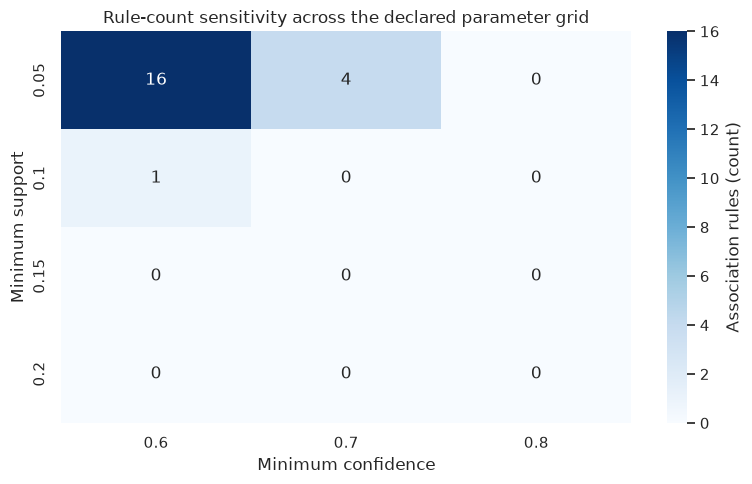

In [5]:
rule_counts = comparison.pivot(index="min_support", columns="min_confidence", values="rules")
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(rule_counts, annot=True, fmt="d", cmap="Blues", ax=ax, cbar_kws={"label": "Association rules (count)"})
ax.set_xlabel("Minimum confidence")
ax.set_ylabel("Minimum support")
ax.set_title("Rule-count sensitivity across the declared parameter grid")
fig.tight_layout()
fig.savefig(PLOTS / "rule_count_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Finding:** Itemsets increase from 15 at 20% support to 166 at 5%. Only the 5% and 10% support settings produce rules anywhere in the declared confidence grid. The 5% / 60% setting yields 16 rules; stricter settings often yield none. These counts measure output sensitivity, not prediction accuracy.

## Exploratory rules: 5% support and 70% confidence

After observing the null baseline rule result, we examine the lower-support setting from the declared grid. This is explicitly exploratory and requires at least 22 joint profiles. The complete exports retain all qualifying rules; the interpretation view uses lift > 1, at most two premise items, and one conclusion.

In [6]:
exploratory_itemsets = mine_itemsets(matrix, support=0.05)
exploratory_raw = mine_rules(exploratory_itemsets, n=len(rows), confidence=0.70)
validate_outputs(exploratory_itemsets, exploratory_raw, counts, len(rows), 0.05, 0.70)
exploratory = serialize_rules(exploratory_raw, rows, counts)
pd.testing.assert_frame_equal(exploratory, pd.read_csv(TABLES / "exploratory_rules.csv"), check_exact=False, atol=1e-12)
display(exploratory)
print("Rule support is count(A union C)/437; confidence is count(A union C)/count(A).")

,antecedents,consequents,antecedent_support,consequent_support,support,confidence,lift,leverage,antecedent_count,consequent_count,support_count,antecedent_length,consequent_length,covered_states,covered_years
0,"[""female_share=middle_tertile"", ""occupancy_rat...","[""illiterate_share=upper_tertile""]",0.086957,0.334096,0.064073,0.736842,2.205479,0.035021,38,146,28,2,1,8,12
1,"[""female_share=upper_tertile"", ""illiterate_sha...","[""occupancy_ratio=within_capacity""]",0.105263,0.411899,0.077803,0.739130,1.794444,0.034445,46,180,34,2,1,8,13
2,"[""illiterate_share=lower_tertile"", ""undertrial...","[""occupancy_ratio=within_capacity""]",0.102975,0.411899,0.075515,0.733333,1.780370,0.033100,45,180,33,2,1,8,12
3,"[""age_18_30_share=upper_tertile"", ""illiterate_...","[""occupancy_ratio=within_capacity""]",0.128146,0.411899,0.093822,0.732143,1.777480,0.041038,56,180,41,2,1,10,13


Rule support is count(A union C)/437; confidence is count(A union C)/count(A).


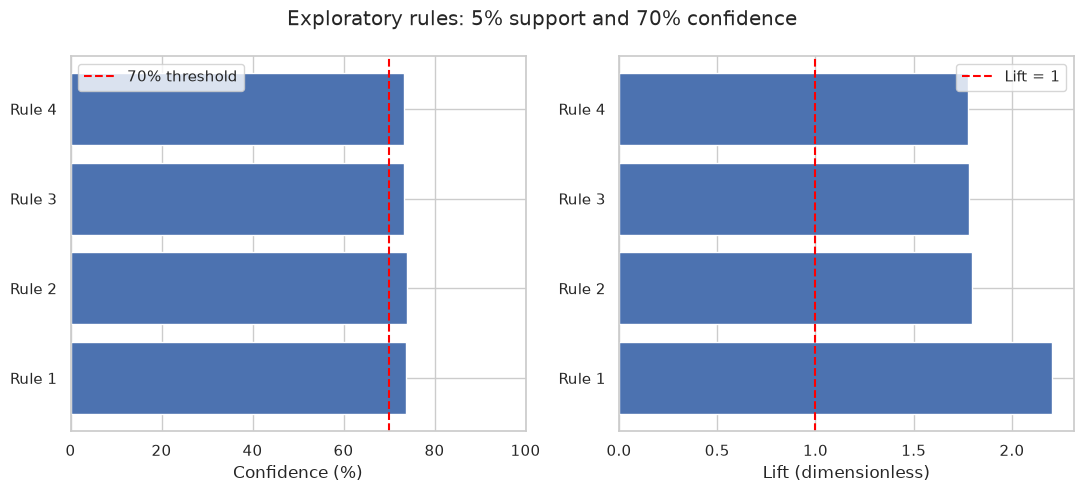

In [7]:
labels = [f"Rule {i+1}" for i in range(len(exploratory))]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(labels, exploratory.confidence * 100)
axes[0].set_xlabel("Confidence (%)")
axes[0].set_xlim(0, 100)
axes[0].axvline(70, color="red", linestyle="--", label="70% threshold")
axes[0].legend()
axes[1].barh(labels, exploratory.lift)
axes[1].axvline(1, color="red", linestyle="--", label="Lift = 1")
axes[1].set_xlabel("Lift (dimensionless)")
axes[1].legend()
fig.suptitle("Exploratory rules: 5% support and 70% confidence")
fig.tight_layout()
fig.savefig(PLOTS / "exploratory_rule_metrics.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## Interpret the actual rules

1. **female_share=middle_tertile + occupancy_ratio=over_150pct → illiterate_share=upper_tertile.** Both sides occur in 28 of 437 profiles (6.41% support). Of 38 profiles satisfying the premise, 28 also satisfy the conclusion (73.68% confidence). The conclusion appears in 146 profiles overall (33.41%); lift is 2.205, and leverage is 0.0350. The joint pattern spans 8 jurisdictions and 12 distinct years. This is a pooled association, not a causal relationship or a held-out prediction.

2. **female_share=upper_tertile + illiterate_share=lower_tertile → occupancy_ratio=within_capacity.** Both sides occur in 34 of 437 profiles (7.78% support). Of 46 profiles satisfying the premise, 34 also satisfy the conclusion (73.91% confidence). The conclusion appears in 180 profiles overall (41.19%); lift is 1.794, and leverage is 0.0344. The joint pattern spans 8 jurisdictions and 13 distinct years. This is a pooled association, not a causal relationship or a held-out prediction.

3. **illiterate_share=lower_tertile + undertrial_share=upper_tertile → occupancy_ratio=within_capacity.** Both sides occur in 33 of 437 profiles (7.55% support). Of 45 profiles satisfying the premise, 33 also satisfy the conclusion (73.33% confidence). The conclusion appears in 180 profiles overall (41.19%); lift is 1.780, and leverage is 0.0331. The joint pattern spans 8 jurisdictions and 12 distinct years. This is a pooled association, not a causal relationship or a held-out prediction.

4. **age_18_30_share=upper_tertile + illiterate_share=lower_tertile → occupancy_ratio=within_capacity.** Both sides occur in 41 of 437 profiles (9.38% support). Of 56 profiles satisfying the premise, 41 also satisfy the conclusion (73.21% confidence). The conclusion appears in 180 profiles overall (41.19%); lift is 1.777, and leverage is 0.0410. The joint pattern spans 10 jurisdictions and 13 distinct years. This is a pooled association, not a causal relationship or a held-out prediction.

## Validation and limits

Independent counting checks every frequent itemset and all disjoint rule partitions across all twelve settings. The tests additionally enumerate the 1,023 family-compatible combinations, including zero-support sets. There are 911 observed positive-support sets. A separate nine-transaction worked example checks the algorithm; it is not used as project data.

These rules describe the same cohort used to fit the bins and mine patterns. Repeated years within states are dependent, and rule coverage is concentrated in 8–10 jurisdictions. No individual-level inference, causality, statistical significance, held-out accuracy or future prediction is established. Lower-support exploration and overlapping rules limit generalization.

Clustering, MAFIA and PySpark comparisons are documented in separate notebooks.

In [8]:
for source in summary["inputs"]:
    from src.preprocessing.cleaning import sha256
    assert sha256(ROOT / source["file"]) == source["sha256"]
assert len(summary["validation"]) == 12
assert all(v["exact_itemset_and_rule_validation"] for v in summary["validation"])
print("Verified: unchanged prepared inputs and exact results across all parameter settings.")

Verified: unchanged prepared inputs and exact results across all parameter settings.
